# Importing Required Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from warnings import filterwarnings
filterwarnings('ignore')

# Importing Aerofit Dataset

In [ ]:
!gdown 1-F3ZCf9nHcxNAq98bsnuqoya9IGVpCew

Downloading...
From: https://drive.google.com/uc?id=1-F3ZCf9nHcxNAq98bsnuqoya9IGVpCew
To: /content/aerofit_treadmill.csv
100% 7.28k/7.28k [00:00<00:00, 32.2MB/s]


In [ ]:
data = pd.read_csv('aerofit_treadmill.csv')

# Initial Data Inspection

In [ ]:
data.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47


### Shape of Data

In [ ]:
data.shape

(180, 9)

### Descriptive Statistics

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB


In [ ]:
data.describe()

,Age,Education,Usage,Fitness,Income,Miles
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,28.788889,15.572222,3.455556,3.311111,53719.577778,103.194444
std,6.943498,1.617055,1.084797,0.958869,16506.684226,51.863605
min,18.000000,12.000000,2.000000,1.000000,29562.000000,21.000000
25%,24.000000,14.000000,3.000000,3.000000,44058.750000,66.000000
50%,26.000000,16.000000,3.000000,3.000000,50596.500000,94.000000
75%,33.000000,16.000000,4.000000,4.000000,58668.000000,114.750000
max,50.000000,21.000000,7.000000,5.000000,104581.000000,360.000000


In [ ]:
data.describe(include='object')

,Product,Gender,MaritalStatus
count,180,180,180
unique,3,2,2
top,KP281,Male,Partnered
freq,80,104,107


### Unique count in each column

In [ ]:
data.nunique()

,0
Product,3
Age,32
Gender,2
Education,8
MaritalStatus,2
Usage,6
Fitness,5
Income,62
Miles,37


### Value Counts

In [ ]:
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns

# Value Counts for all Numeric Columns
for col in numeric_cols:
  print(f"\nValue Counts for {col}:")
  print(data[col].value_counts())


Value Counts for Age:
Age
25    25
23    18
24    12
26    12
28     9
33     8
35     8
22     7
30     7
27     7
38     7
21     7
31     6
34     6
29     6
20     5
40     5
19     4
32     4
37     2
45     2
48     2
47     2
18     1
41     1
39     1
36     1
43     1
46     1
44     1
50     1
42     1
Name: count, dtype: int64

Value Counts for Education:
Education
16    85
14    55
18    23
15     5
13     5
12     3
21     3
20     1
Name: count, dtype: int64

Value Counts for Usage:
Usage
3    69
4    52
2    33
5    17
6     7
7     2
Name: count, dtype: int64

Value Counts for Fitness:
Fitness
3    97
5    31
2    26
4    24
1     2
Name: count, dtype: int64

Value Counts for Income:
Income
45480     14
52302      9
53439      8
54576      8
46617      8
          ..
85906      1
99601      1
103336     1
95866      1
95508      1
Name: count, Length: 62, dtype: int64

Value Counts for Miles:
Miles
85     27
95     12
66     10
75     10
47      9
106     9
113     8
9

# Business Problem
The market research team at AeroFit wants to identify the characteristics of the target audience for each type of treadmill offered by the company, to provide a better recommendation of the treadmills to the new customers. The team decides to investigate whether there are differences across the product with respect to customer characteristics.

## Missing Value Identification

In [ ]:
np.sum(data.isnull())

,0
Product,0
Age,0
Gender,0
Education,0
MaritalStatus,0
Usage,0
Fitness,0
Income,0
Miles,0


## Checking Outliers in Dataset

### Box plots

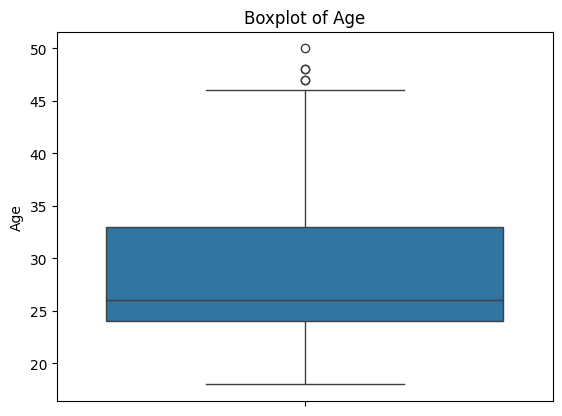

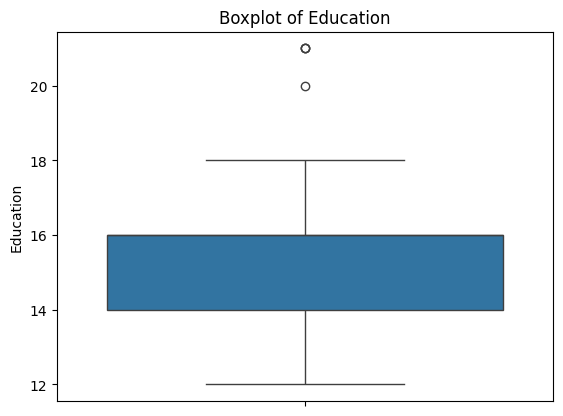

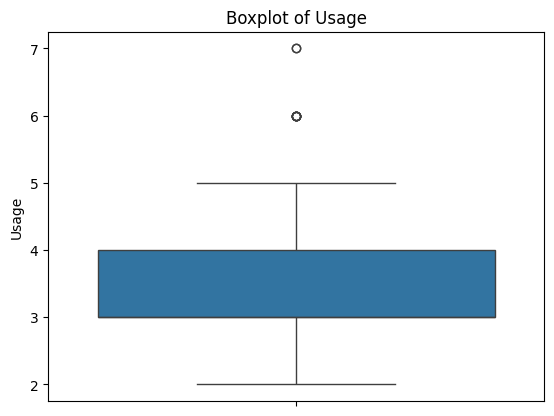

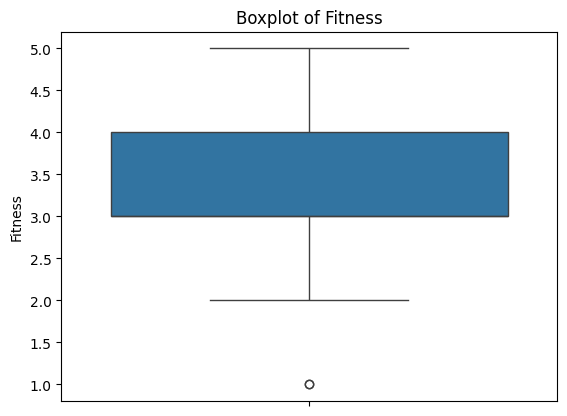

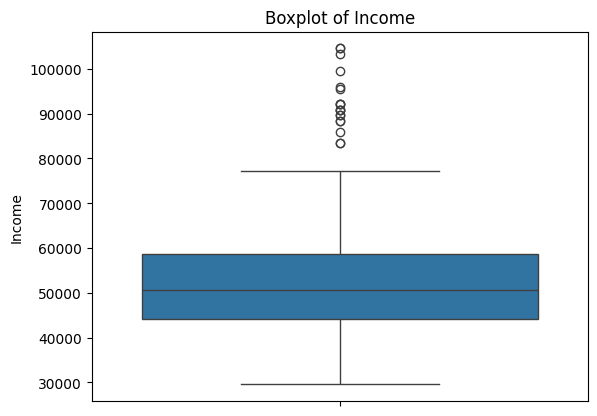

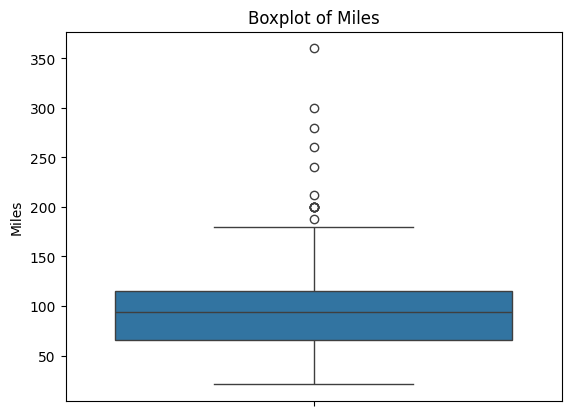

In [ ]:
# Extracting the numerical columns
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns

# Boxplot for all columns
for col in numeric_cols:
  plt.figure()
  sns.boxplot(y=data[col])
  plt.title(f"Boxplot of {col}")
  plt.show()

### Mean and Median Difference

In [ ]:
for col in data.select_dtypes(include=np.number).columns:
    print(f"{col} -> Mean: {data[col].mean():.2f}, Median: {data[col].median():.2f}")

Age -> Mean: 28.79, Median: 26.00
Education -> Mean: 15.57, Median: 16.00
Usage -> Mean: 3.46, Median: 3.00
Fitness -> Mean: 3.31, Median: 3.00
Income -> Mean: 53719.58, Median: 50596.50
Miles -> Mean: 103.19, Median: 94.00


### IQR Method

In [ ]:
for col in numeric_cols:
    Q1 = np.percentile(data[col], 25)
    Q3 = np.percentile(data[col], 75)

    IQR = Q3 - Q1

    left_whisker = Q1 - 1.5 * IQR
    right_whisker = Q3 + 1.5 * IQR

    outliers = data[(data[col] < left_whisker) | (data[col] > right_whisker)]
    print(f"{col}: {len(outliers)} outliers")

Age: 5 outliers
Education: 4 outliers
Usage: 9 outliers
Fitness: 2 outliers
Income: 19 outliers
Miles: 13 outliers


## Correlation between Product Purchased and Other Features

### Gender vs Product

Counts:
 Product  KP281  KP481  KP781
Gender                      
Female      40     29      7
Male        40     31     33

Conditional Probability:
 Product     KP281     KP481     KP781
Gender                               
Female   0.526316  0.381579  0.092105
Male     0.384615  0.298077  0.317308


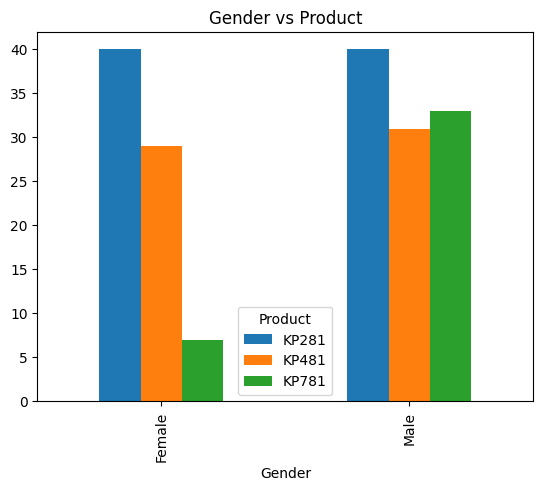

In [ ]:
# Gender wise product bifurcation
gender_ct = pd.crosstab(data['Gender'], data['Product'])

# Conditional Probability: For a given gender, the probability of each product
# --> [P(Product∣Gender)]
gender_conditional = pd.crosstab(data['Gender'], data['Product'], normalize='index')

print("Counts:\n", gender_ct)
print("\nConditional Probability:\n", gender_conditional)

gender_ct.plot(kind='bar')
plt.title("Gender vs Product")
plt.show()

### Marital Status vs Product

Counts:
 Product        KP281  KP481  KP781
MaritalStatus                     
Partnered         48     36     23
Single            32     24     17

Conditional Probability:
 Product           KP281     KP481     KP781
MaritalStatus                              
Partnered      0.448598  0.336449  0.214953
Single         0.438356  0.328767  0.232877


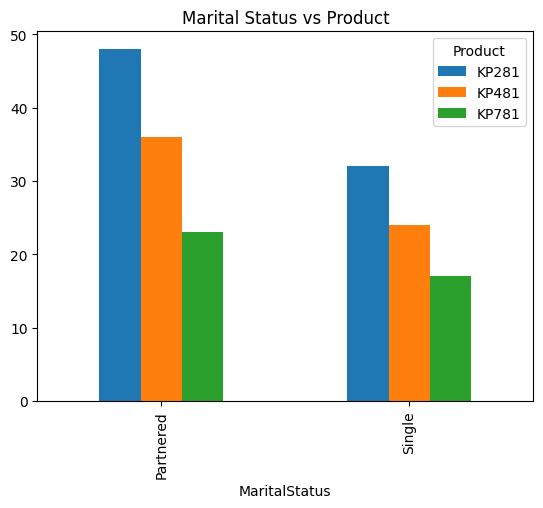

In [ ]:
# Marital status wise product bifurcation
marital_ct = pd.crosstab(data['MaritalStatus'], data['Product'])

# Conditional Probability
marital_conditional = pd.crosstab(data['MaritalStatus'], data['Product'],
                                  normalize='index')

print("Counts:\n", marital_ct)
print("\nConditional Probability:\n", marital_conditional)

marital_ct.plot(kind='bar')
plt.title("Marital Status vs Product")
plt.show()

### Age vs Product

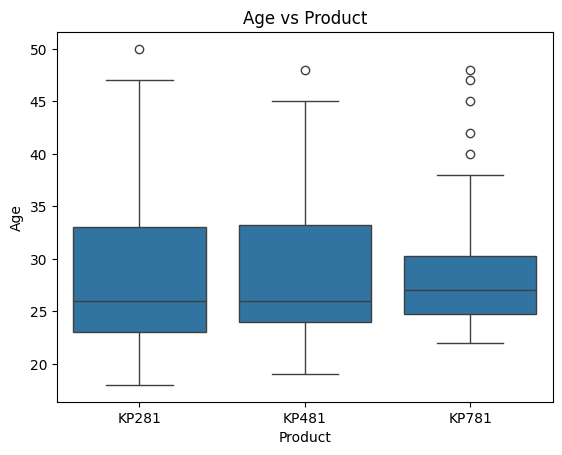

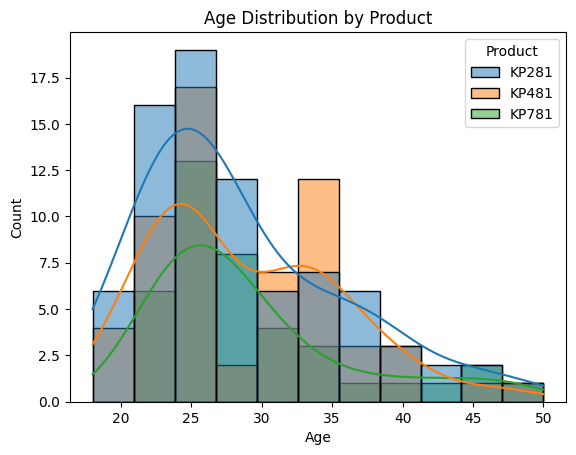

In [ ]:
plt.figure()
sns.boxplot(x='Product', y='Age', data=data)
plt.title("Age vs Product")
plt.show()

plt.figure()
sns.histplot(data=data, x='Age', hue='Product', kde=True)
plt.title("Age Distribution by Product")
plt.show()

### Income vs Product

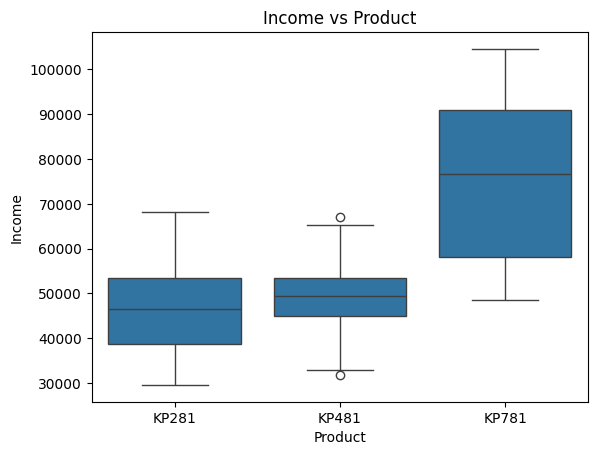

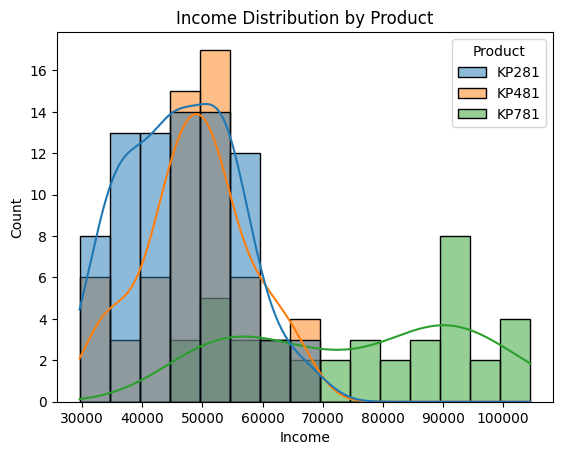

In [ ]:
plt.figure()
sns.boxplot(x='Product', y='Income', data=data)
plt.title("Income vs Product")
plt.show()

plt.figure()
sns.histplot(data=data, x='Income', hue='Product', kde=True)
plt.title("Income Distribution by Product")
plt.show()

## Marginal Probability

In [ ]:
marginal_ct = pd.crosstab(data['Product'], columns='Count')
marginal_ct['Probability'] = marginal_ct['Count'] / marginal_ct['Count'].sum()
marginal_ct['Percentage (%)'] = marginal_ct['Probability'] * 100

print(marginal_ct)

col_0    Count  Probability  Percentage (%)
Product                                    
KP281       80     0.444444       44.444444
KP481       60     0.333333       33.333333
KP781       40     0.222222       22.222222


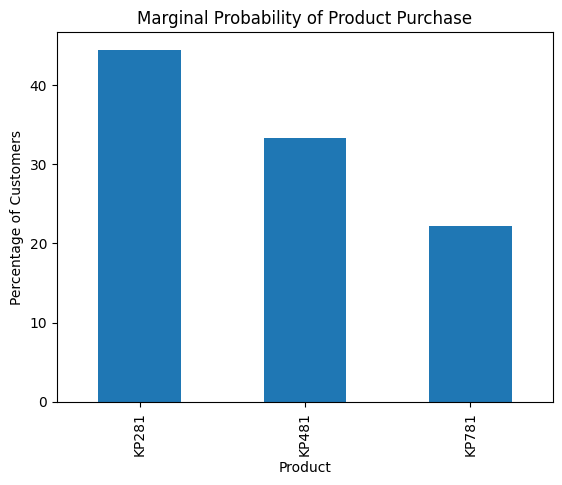

In [ ]:
marginal_ct['Percentage (%)'].plot(kind='bar')
plt.ylabel("Percentage of Customers")
plt.title("Marginal Probability of Product Purchase")
plt.show()

## Correlation Analysis

Correlation Matrix:
                Age  Education     Usage   Fitness    Income     Miles
Age        1.000000   0.280496  0.015064  0.061105  0.513414  0.036618
Education  0.280496   1.000000  0.395155  0.410581  0.625827  0.307284
Usage      0.015064   0.395155  1.000000  0.668606  0.519537  0.759130
Fitness    0.061105   0.410581  0.668606  1.000000  0.535005  0.785702
Income     0.513414   0.625827  0.519537  0.535005  1.000000  0.543473
Miles      0.036618   0.307284  0.759130  0.785702  0.543473  1.000000


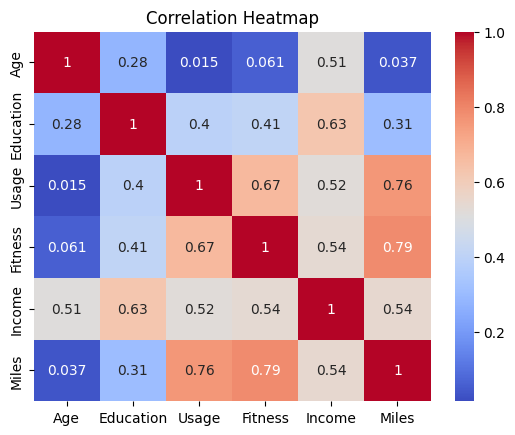

In [ ]:
numeric_cols = data.select_dtypes(include=['int64', 'float64'])

corr = numeric_cols.corr()

print("Correlation Matrix:")
print(corr)

plt.figure()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Gender Wise distribution of Product- KP781 treadmill

### Male

In [ ]:
prob_male_kp781 = pd.crosstab(data['Gender'], data['Product'],
                              normalize='all').loc['Male', 'KP781']
print("P(Male and KP781):", prob_male_kp781)

# Conditional probability
prob_kp781_given_male = pd.crosstab(data['Gender'], data['Product'],
                                    normalize='index').loc['Male', 'KP781']
print("P(KP781 | Male):", prob_kp781_given_male)

P(Male and KP781): 0.18333333333333332
P(KP781 | Male): 0.3173076923076923


### Female

In [ ]:
prob_female_kp781 = pd.crosstab(data['Gender'], data['Product'],
                                normalize='all').loc['Female', 'KP781']
print("P(Female and KP781):", prob_female_kp781)

# Conditional probability
prob_kp781_given_female = pd.crosstab(data['Gender'], data['Product'],
                                      normalize='index').loc['Female', 'KP781']
print("P(KP781 | Female):", prob_kp781_given_female)

P(Female and KP781): 0.03888888888888889
P(KP781 | Female): 0.09210526315789473


## Customer Profiling by Product

In [ ]:
profile = data.groupby('Product').mean(numeric_only=True)
print("Customer Profile (Average values):")
print(profile)

Customer Profile (Average values):
           Age  Education     Usage  Fitness     Income       Miles
Product                                                            
KP281    28.55  15.037500  3.087500   2.9625  46418.025   82.787500
KP481    28.90  15.116667  3.066667   2.9000  48973.650   87.933333
KP781    29.10  17.325000  4.775000   4.6250  75441.575  166.900000


## Miles & Fitness Impact

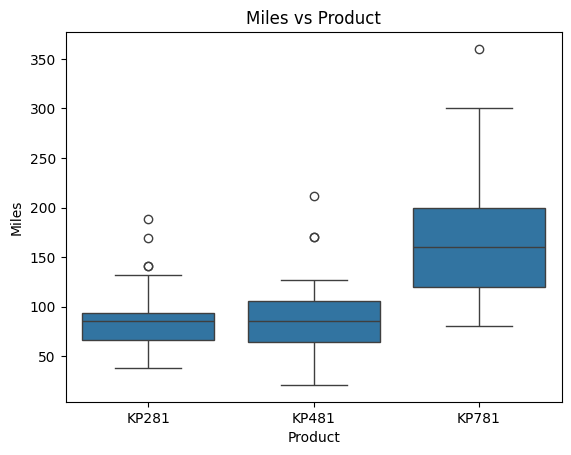

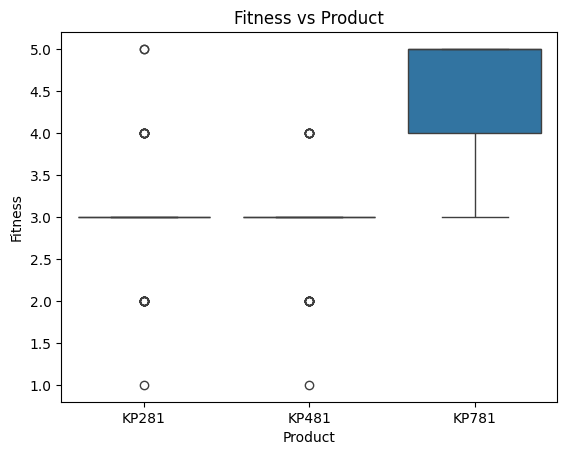

In [ ]:
plt.figure()
sns.boxplot(x='Product', y='Miles', data=data)
plt.title("Miles vs Product")
plt.show()

plt.figure()
sns.boxplot(x='Product', y='Fitness', data=data)
plt.title("Fitness vs Product")
plt.show()

## Pairplot

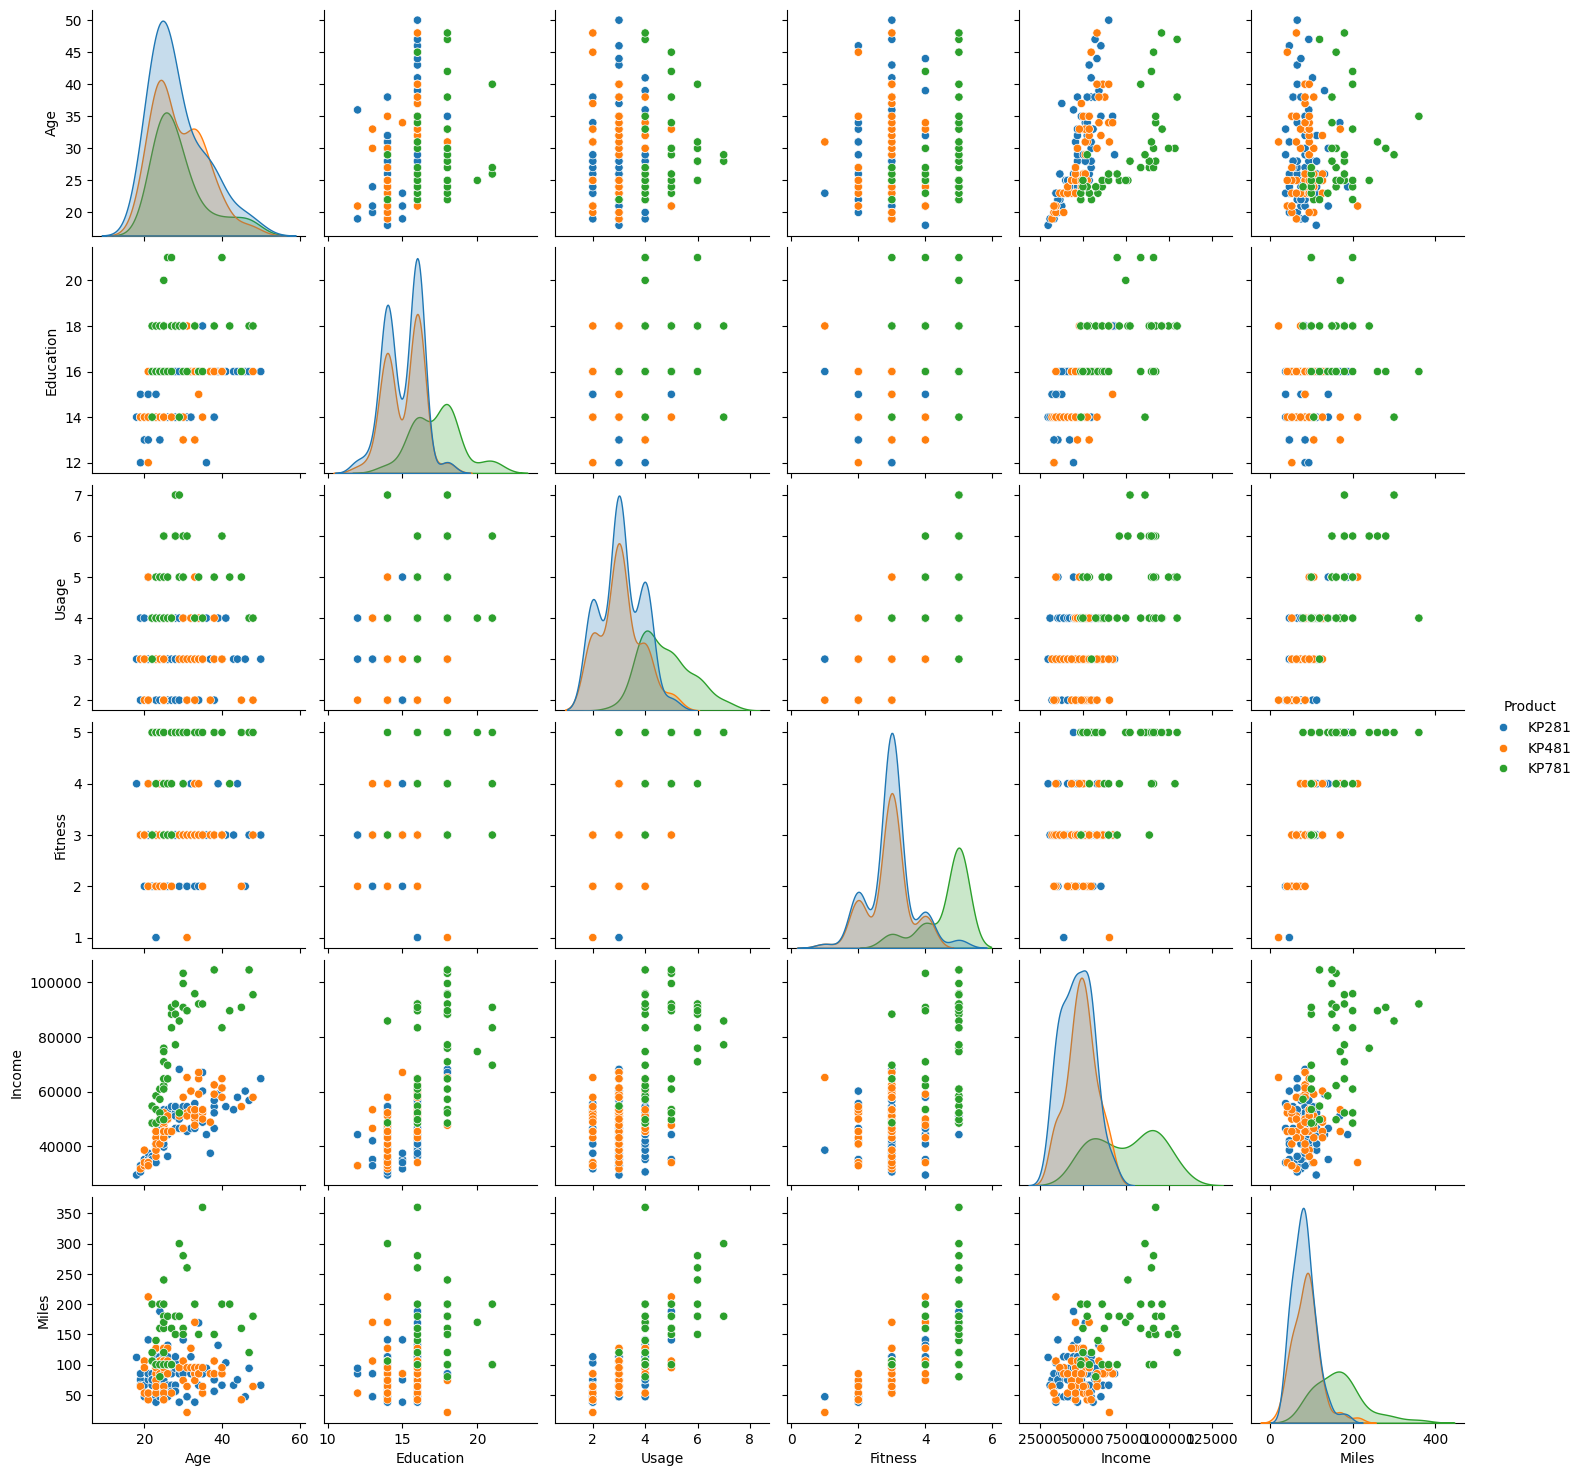

In [ ]:
sns.pairplot(data, hue='Product')
plt.show()

## Income Segmentation

In [ ]:
data['Income_Category'] = pd.cut(data['Income'],
                                 bins=[0,50000,70000,120000],
                                 labels=['Low','Medium','High'])
pd.crosstab(data['Income_Category'], data['Product'], normalize='index')

Product,KP281,KP481,KP781
Income_Category,,,
Low,0.578313,0.361446,0.060241
Medium,0.432432,0.405405,0.162162
High,0.000000,0.000000,1.000000


## Summary Table

In [ ]:
summary = data.groupby('Product').agg({
    'Age':'mean',
    'Income':'mean',
    'Fitness':'mean',
    'Usage':'mean',
    'Miles':'mean',
    'Education':'mean'
})

print(summary)


           Age     Income  Fitness     Usage       Miles  Education
Product                                                            
KP281    28.55  46418.025   2.9625  3.087500   82.787500  15.037500
KP481    28.90  48973.650   2.9000  3.066667   87.933333  15.116667
KP781    29.10  75441.575   4.6250  4.775000  166.900000  17.325000


# Final Observations

### Data Understanding & Structure

Total observations: 180 customers

Products:

KP281 → 80 customers (44.4%)

KP481 → 60 customers (33.3%)

KP781 → 40 customers (22.2%)

Key Numeric Averages (Overall)

Average Age: 28.8 years

Average Income: $53,719

Average Usage: 3.45 times/week

Average Fitness: 3.31

Average Miles/week: 103 miles

***Business Insight***: This suggests a relatively young, moderately active
customer base.

### Missing Values

There are no missing values in the data.

### Outlier Detection

Outliers detected in:

Income (19 outliers)

Miles (13 outliers)

Usage (9 outliers)

Age (5 outliers)

***Business Insight:***
High-income and high-mile customers likely represent premium-segment buyers (KP781). These records may represent a high-value segment.

### Marginal Probability

***Business Insight:***

1. KP281 is the most popular entry-level model. KP781 is a premium niche product (~22% share).
2. This distribution suggests a pyramid market structure: Entry > Mid > Premium.









### Gender vs Product

Female:

KP281 → 52.6%

KP481 → 38.2%

KP781 → 9.2%

Male:

KP281 → 38.5%

KP481 → 29.8%

KP781 → 31.7%

***Business Insight:***

Probability (Male buying KP781) = 18.3% overall

Probability (Female buying KP781) = 3.9% overall

Nearly 32% of males buy KP781 whereas only 9% of females buy KP781.

1. KP781 strongly appeals to males.
2. Marketing for KP781 should target male, high-performance messaging.
3. There is an untapped female premium segment opportunity.

### Marital Status vs Product

***Business Insight:***
Conditional probabilities are very similar between Partnered and Single.
Marital status has minimal impact on product choice.

### Customer Profiling by Product

***KP281 (Entry Level)***

Lower income (~$46K)

Moderate fitness

Moderate usage

Walkers / beginners

***Target Audience:***
Young working professional starting fitness journey.

***KP481 (Mid-Level)***

Slightly higher income than KP281

Similar usage & fitness

Transitional users

***Target Audience:***
Regular fitness enthusiast upgrading from entry model.

***KP781 (Premium Model)***

Income: $75K+

Fitness: 4.6/5

Usage: 4.8 times/week

167 miles/week

Highly educated (17+ years)

***Target Audience:***
1. Serious runners / high-performance users.
2. Likely fitness-driven lifestyle.

### Correlation Analysis

***Strong correlations:***

Usage ↔ Miles (0.76)

Fitness ↔ Miles (0.78)

Fitness ↔ Usage (0.67)

Income ↔ Education (0.63)

***Business Insight:***

More fit customers use treadmill more.

Higher education → higher income → more premium purchase capacity.

### Gender Wise distribution of Product- KP781 treadmill

***Male Customers***
Overall: 18.3%

Conditional (given male): 31.7%

***Drivers for KP781 purchase:***

1. High income
2. High fitness
3. High usage
4. Higher education

***Market Segmentation Strategy***

Segment customers into 3 tiers:

| Segment   | Characteristics             | Product |
|-----------|----------------------------|---------|
| Beginner  | Low income, low fitness    | KP281   |
| Regular   | Moderate fitness           | KP481   |
| Athlete   | High income, high usage    | KP781   |


# Business Recommendations


***KP281***

1. Promote affordability
2. Beginner fitness campaigns
3. EMI/payment flexibility

***KP481***

1. Promote as upgrade product

***KP781***

1. Performance branding
2. Endurance/athlete marketing
3. Target high-income zip codes
4. Focus on male segment, but premium female segment can be explored.